In [76]:
# ============================================================
# USER-EDITABLE CO WHITE DWARF SETTINGS
# ============================================================

# ---------- STAR ----------
MASS_MSUN = 3.1
INITIAL_Z = 0.0200

# ---------- SPEED / TERMINATION ----------
# Higher = potentially faster but less detailed evolution
MAX_MODEL_NUMBER = 10000

# Stop removing the envelope when log10(Teff) reaches this value
LOG_TEFF_LIMIT = 4.8

# ---------- MESA NUMERICAL SETTINGS ----------
# Larger values generally mean fewer/simpler mesh points
MESH_DELTA_COEFF = 2.0

# Larger value = less strict timestep control
VARCONTROL_TARGET = 3e-3

# Maximum timestep in years
MAX_YEARS_FOR_TIMESTEP = 1e9

# ---------- OUTPUT ----------
HISTORY_INTERVAL = 20
PROFILE_INTERVAL = 100
TERMINAL_INTERVAL = 50

# ---------- RUN CONTROL ----------
OVERWRITE_RUN = True
RUN_MESA = True


print("======================================")
print("CO-WD RUN SETTINGS")
print("======================================")
print(f"Initial mass:        {MASS_MSUN} Msun")
print(f"Initial metallicity: Z = {INITIAL_Z}")
print(f"Max model number:    {MAX_MODEL_NUMBER}")
print(f"log(Teff) limit:     {LOG_TEFF_LIMIT}")
print(f"Mesh coefficient:    {MESH_DELTA_COEFF}")
print(f"Varcontrol target:   {VARCONTROL_TARGET}")
print(f"Max timestep:        {MAX_YEARS_FOR_TIMESTEP} yr")
print(f"History interval:    {HISTORY_INTERVAL}")
print(f"Profile interval:    {PROFILE_INTERVAL}")

CO-WD RUN SETTINGS
Initial mass:        3.1 Msun
Initial metallicity: Z = 0.02
Max model number:    10000
log(Teff) limit:     4.8
Mesh coefficient:    2.0
Varcontrol target:   0.003
Max timestep:        1000000000.0 yr
History interval:    20
Profile interval:    100


In [77]:
# ============================================================
# PATHS
# ============================================================

import os
import re
import shutil
import subprocess
from pathlib import Path

os.environ["MESA_DIR"] = "/Users/mchau/mesa"

PROJECT_ROOT = Path("/Users/mchau/mesa_tutorial")
WD_DIR = PROJECT_ROOT / "WD" / "make_co_wd"

print("MESA_DIR:", os.environ["MESA_DIR"])
print("Source directory:", WD_DIR)

MESA_DIR: /Users/mchau/mesa
Source directory: /Users/mchau/mesa_tutorial/WD/make_co_wd


In [78]:
# ============================================================
# CREATE CUSTOM RUN DIRECTORY
# ============================================================

mass_label = f"{MASS_MSUN:.1f}".replace(".", "p")
z_label = f"{INITIAL_Z:.4f}".replace(".", "p")

RUN_DIR = (
    PROJECT_ROOT
    / "WD"
    / f"CO_WD_{mass_label}Msun_Z{z_label}"
)

print("RUN_DIR =", RUN_DIR)

if RUN_DIR.exists():

    if OVERWRITE_RUN:
        print("Removing previous run...")
        shutil.rmtree(RUN_DIR)
    else:
        raise FileExistsError(
            f"{RUN_DIR} already exists. "
            "Set OVERWRITE_RUN = True or choose different parameters."
        )

RUN_DIR.mkdir(parents=True)

print("Created:", RUN_DIR)

RUN_DIR = /Users/mchau/mesa_tutorial/WD/CO_WD_3p1Msun_Z0p0200
Created: /Users/mchau/mesa_tutorial/WD/CO_WD_3p1Msun_Z0p0200


In [79]:
# ============================================================
# COPY MESA SETUP
# ============================================================

files_to_copy = [
    "star",
    "inlist",
    "inlist_common",
    "inlist_remove_env",
    "inlist_remove_env_header",
    "inlist_settle",
    "inlist_settle_header",
    "inlist_zams",
    "inlist_zams_header",
    "inlist_co_core",
    "inlist_co_core_header",
    "inlist_to_end_he_core_burn",
    "inlist_to_end_he_core_burn_header",
    "history_columns.list",
    "profile_columns.list",
    "testhub.yml",
    "rn",
    "rn1",
    "re",
    "ck",
    "zams.mod",
    "end_he_core_burn.mod",
    "co_core.mod",
]

for name in files_to_copy:

    source = WD_DIR / name
    destination = RUN_DIR / name

    if not source.exists():
        print("WARNING — missing:", name)
        continue

    if source.is_file():
        shutil.copy2(source, destination)
        print("Copied:", name)

print("\nSetup copied successfully.")

Copied: star
Copied: inlist
Copied: inlist_common
Copied: inlist_remove_env
Copied: inlist_remove_env_header
Copied: inlist_settle
Copied: inlist_settle_header
Copied: inlist_zams
Copied: inlist_zams_header
Copied: inlist_co_core
Copied: inlist_co_core_header
Copied: inlist_to_end_he_core_burn
Copied: inlist_to_end_he_core_burn_header
Copied: history_columns.list
Copied: profile_columns.list
Copied: testhub.yml
Copied: rn
Copied: rn1
Copied: re
Copied: ck
Copied: zams.mod
Copied: end_he_core_burn.mod
Copied: co_core.mod

Setup copied successfully.


In [80]:
# ============================================================
# APPLY EDITABLE SETTINGS TO MESA INLISTS
# ============================================================

# ------------------------------------------------------------
# inlist_common
# ------------------------------------------------------------

common = RUN_DIR / "inlist_common"
text = common.read_text()

text, n_mass = re.subn(
    r"(^\s*initial_mass\s*=\s*)[-+0-9.eEdD]+",
    rf"\g<1>{MASS_MSUN:.6g}d0",
    text,
    flags=re.MULTILINE
)

text, n_z = re.subn(
    r"(^\s*initial_z\s*=\s*)[-+0-9.eEdD]+",
    rf"\g<1>{INITIAL_Z:.6g}d0",
    text,
    flags=re.MULTILINE
)

common.write_text(text)


# ------------------------------------------------------------
# inlist_remove_env
# ------------------------------------------------------------

remove_env = RUN_DIR / "inlist_remove_env"
text = remove_env.read_text()

text, n_max = re.subn(
    r"(^\s*max_model_number\s*=\s*)\d+",
    rf"\g<1>{MAX_MODEL_NUMBER}",
    text,
    flags=re.MULTILINE
)

text, n_teff = re.subn(
    r"(^\s*log_Teff_upper_limit\s*=\s*)[-+0-9.eEdD]+",
    rf"\g<1>{LOG_TEFF_LIMIT}",
    text,
    flags=re.MULTILINE
)

remove_env.write_text(text)


# ------------------------------------------------------------
# Check replacements
# ------------------------------------------------------------

print("Settings updated:")
print("  initial_mass:", n_mass)
print("  initial_z:", n_z)
print("  max_model_number:", n_max)
print("  log_Teff_upper_limit:", n_teff)

Settings updated:
  initial_mass: 1
  initial_z: 1
  max_model_number: 1
  log_Teff_upper_limit: 1


In [81]:
# ============================================================
# APPLY SPEED / OUTPUT SETTINGS
# ============================================================

common = RUN_DIR / "inlist_common"
text = common.read_text()

# Mesh
text = re.sub(
    r"(^\s*mesh_delta_coeff\s*=\s*)[-+0-9.eEdD]+",
    rf"\g<1>{MESH_DELTA_COEFF}",
    text,
    flags=re.MULTILINE
)

# Timestep control
text = re.sub(
    r"(^\s*varcontrol_target\s*=\s*)[-+0-9.eEdD]+",
    rf"\g<1>{VARCONTROL_TARGET}",
    text,
    flags=re.MULTILINE
)

text = re.sub(
    r"(^\s*max_years_for_timestep\s*=\s*)[-+0-9.eEdD]+",
    rf"\g<1>{MAX_YEARS_FOR_TIMESTEP:.6g}",
    text,
    flags=re.MULTILINE
)

# Output frequency
text = re.sub(
    r"(^\s*history_interval\s*=\s*)\d+",
    rf"\g<1>{HISTORY_INTERVAL}",
    text,
    flags=re.MULTILINE
)

text = re.sub(
    r"(^\s*profile_interval\s*=\s*)\d+",
    rf"\g<1>{PROFILE_INTERVAL}",
    text,
    flags=re.MULTILINE
)

text = re.sub(
    r"(^\s*terminal_interval\s*=\s*)\d+",
    rf"\g<1>{TERMINAL_INTERVAL}",
    text,
    flags=re.MULTILINE
)

common.write_text(text)

print("Speed/output settings applied.")

Speed/output settings applied.


In [73]:
# ============================================================
# VERIFY FINAL SETTINGS
# ============================================================

print("\n========== inlist_common ==========")

text = (RUN_DIR / "inlist_common").read_text()

for line in text.splitlines():
    if any(key in line for key in [
        "initial_mass",
        "initial_z",
        "mesh_delta_coeff",
        "varcontrol_target",
        "max_years_for_timestep",
        "history_interval",
        "profile_interval",
        "terminal_interval",
    ]):
        print(line)


print("\n========== inlist_remove_env ==========")

text = (RUN_DIR / "inlist_remove_env").read_text()

for line in text.splitlines():
    if any(key in line for key in [
        "max_model_number",
        "log_Teff_upper_limit",
    ]):
        print(line)

CUSTOM CO WD RUN

Run directory:
/Users/mchau/mesa_tutorial/WD/CO_WD_3p1Msun_Z0p0200

Mass / metallicity:
  initial_mass = 3.1d0 ! this default produces a ~0.6 Msun WD.
  initial_z    = 0.02d0

Stopping conditions:
  max_model_number     = 5000
  log_Teff_upper_limit = 4.8

Files:
  inlist                         ✓
  inlist_common                  ✓
  inlist_remove_env              ✓
  zams.mod                       ✓
  end_he_core_burn.mod           ✓
  co_core.mod                    ✓


In [83]:
# ============================================================
# RUN MESA — QUIET MODE
# ============================================================

import os
import subprocess
from pathlib import Path

os.chdir(RUN_DIR)

print("======================================")
print("STARTING MESA")
print("======================================")
print("Run directory:", RUN_DIR)
print("Output is being saved to mesa_output.txt")
print()

output_file = RUN_DIR / "mesa_output.txt"

with open(output_file, "w") as f:
    process = subprocess.Popen(
        ["./star"],
        cwd=RUN_DIR,
        stdout=f,
        stderr=subprocess.STDOUT,
        text=True,
    )

    print("MESA PID:", process.pid)

    return_code = process.wait()

print()
print("======================================")
print("MESA FINISHED")
print("======================================")
print("Return code:", return_code)

STARTING MESA
Run directory: /Users/mchau/mesa_tutorial/WD/CO_WD_3p1Msun_Z0p0200
Output is being saved to mesa_output.txt

MESA PID: 56264

MESA FINISHED
Return code: 0


Using profile:
/Users/mchau/mesa_tutorial/WD/CO_WD_3p1Msun_Z0p0200/LOGS/profile100.data

Header found on line: 5
Number of columns: 145


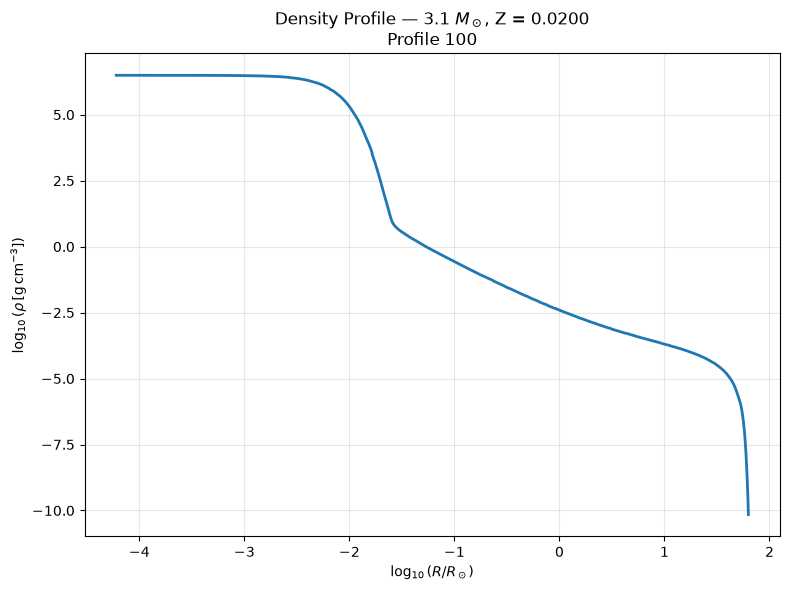

In [84]:
# ============================================================
# DENSITY PROFILE — CO WD RUN
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Your run
RUN_DIR = Path(
    "/Users/mchau/mesa_tutorial/WD/CO_WD_3p1Msun_Z0p0200"
)

LOGS_DIR = RUN_DIR / "LOGS"

# ------------------------------------------------------------
# Find the latest profile
# ------------------------------------------------------------

profiles = sorted(
    LOGS_DIR.glob("profile*.data"),
    key=lambda p: int(p.stem.replace("profile", ""))
)

if not profiles:
    raise FileNotFoundError("No profile*.data files found.")

profile_file = profiles[-1]

print("Using profile:")
print(profile_file)
print()

# ------------------------------------------------------------
# Read profile
# ------------------------------------------------------------

with open(profile_file, "r") as f:
    lines = f.readlines()

# Find header
header_line = None

for i, line in enumerate(lines):
    if "zone" in line and "logR" in line:
        header_line = i
        break

if header_line is None:
    raise ValueError("Could not find profile header.")

column_names = lines[header_line].split()

print("Header found on line:", header_line)
print("Number of columns:", len(column_names))

# Read data
profile = pd.read_csv(
    profile_file,
    sep=r"\s+",
    skiprows=header_line + 1,
    names=column_names,
    engine="python"
)

# ------------------------------------------------------------
# Plot density
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    profile["logR"],
    profile["logRho"],
    linewidth=2
)

plt.xlabel(r"$\log_{10}(R/R_\odot)$")
plt.ylabel(r"$\log_{10}(\rho\,[\mathrm{g\,cm^{-3}}])$")
plt.title(
    f"Density Profile — 3.1 $M_\\odot$, Z = 0.0200\n"
    f"Profile {profile_file.stem.replace('profile', '')}"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'data' is not defined